In [54]:
from pathlib import Path
import pandas as pd
import numpy as np
from feature_engine.encoding import CountFrequencyEncoder
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
import shap
import mlflow.sklearn
import mlflow


import config

#import warnings
#warnings.filterwarnings('ignore')

In [55]:
# define Mlflow env. settings
mlflow.set_tracking_uri(uri=config.mlflow_uri)
%env MLFLOW_TRACKING_URI= config.mlflow_db
%env mlflow_tracking_username = config.mlflow_un
%env mlflow_tracking_password = config.mlflow_pw

#import os
#os.environ['OMP_NUM_THREADS'] = '1'

env: MLFLOW_TRACKING_URI=config.mlflow_db
env: mlflow_tracking_username=config.mlflow_un
env: mlflow_tracking_password=config.mlflow_pw


In [56]:
customerList = ["X7"] #,"X3","X4","X1","X2","X6"] # "X5","X7","X8"

#Replace with dynamic code later Not full list of audit types
# Full list
#FilterTypeList = ['AddTest','Aliquot','Authorize','CalculationUpdate','Cancel','CancelResult','CancelSample','CancelTest','CreateQCSample','EditTests','FileImport','ModifyBaseDate','ModifySample','Prepare','ReactivateSample','ReceiveSample','Reject','ReleaseSample','RemoveTest','ReSample','RestoreResult','RestoreSample','RestoreTest','ReviewAuditTrail','Reviewed','TableUpdate','UnReceiveSample','UpdateBatch','UpdateLot'] 
# Non-problematic list
FilterTypeList = ['AddTest','Aliquot','Authorize','CalculationUpdate','CancelSample','CancelTest','EditTests','FileImport','ModifySample','ReactivateSample','ReceiveSample','UnReceiveSample']  
# Testing
#FilterTypeList = ['AddTest']


#Details: ERRR on field: sample_size: Parameter sample_size must be in interval [2, 100000] but it is 256'
#x5 ['CancelResult','ModifyBaseDate','Prepare','Reject','ReSample','RemoveTest','ReviewAuditTrail','Reviewed','UpdateBatch'] 
#x7 ['Cancel','CreateQCSample','ReleaseSample''RestoreResult','RestoreSample','TableUpdate','UpdateLot']
#x8 ['RestoreSample'] 
#mlflow.autolog()

PermutationExplainer explainer: 3874it [29:47,  2.15it/s]                          


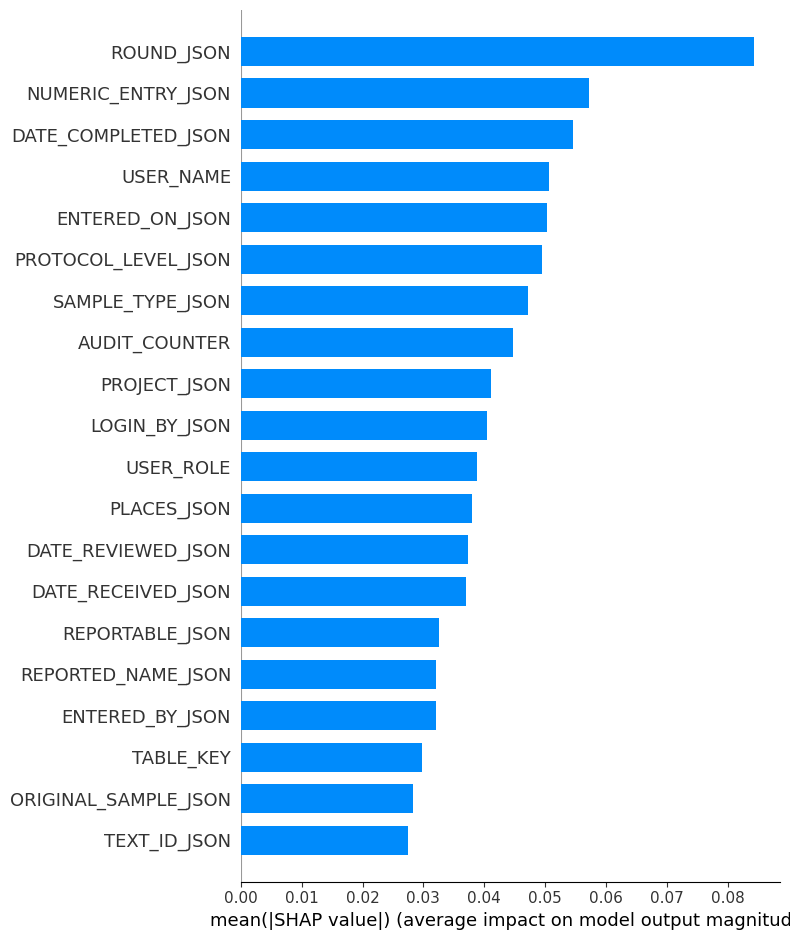

PermutationExplainer explainer: 8311it [1:05:22,  2.11it/s]                          


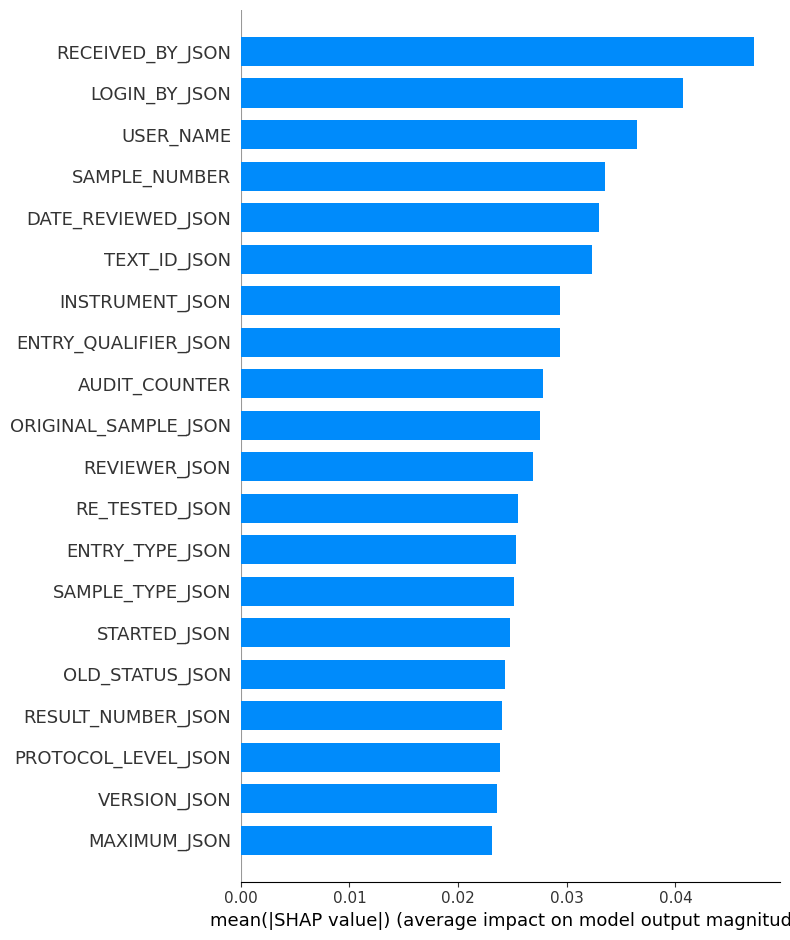

PermutationExplainer explainer: 1150it [05:13,  3.54it/s]                          


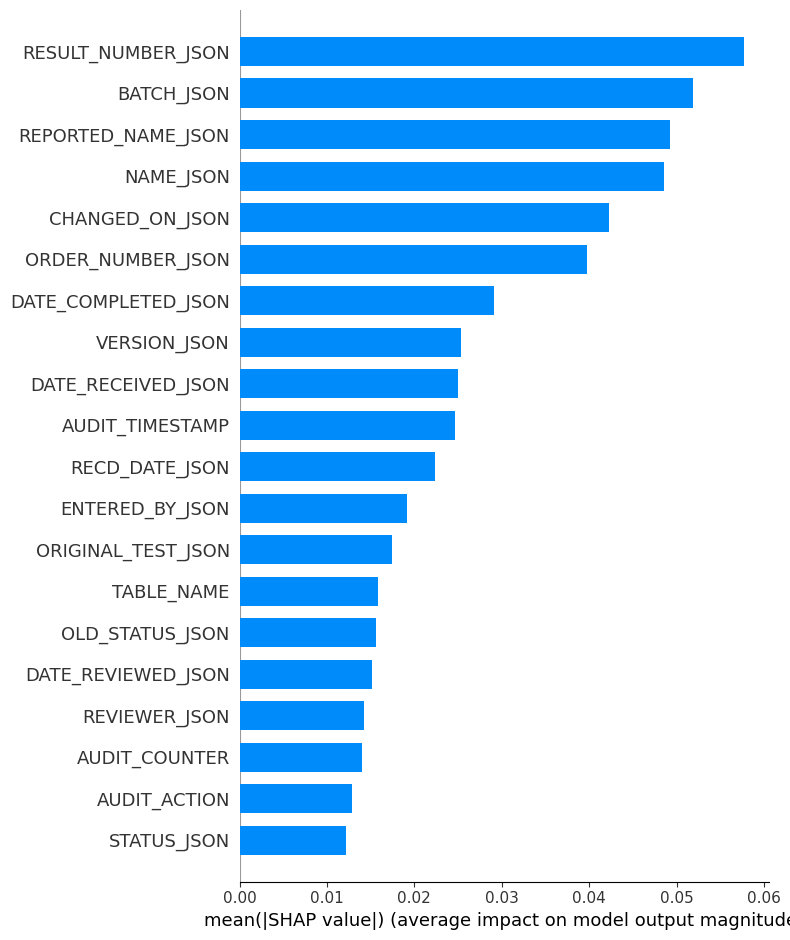

PermutationExplainer explainer: 4305it [37:25,  1.91it/s]                          


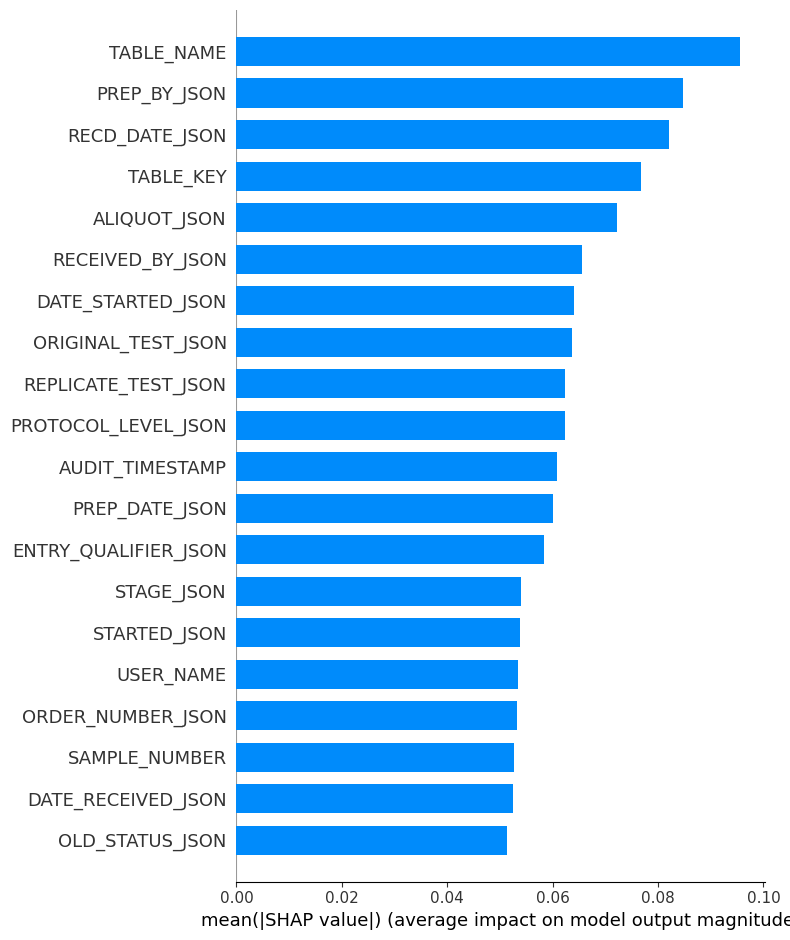

PermutationExplainer explainer: 5531it [51:02,  1.80it/s]                           


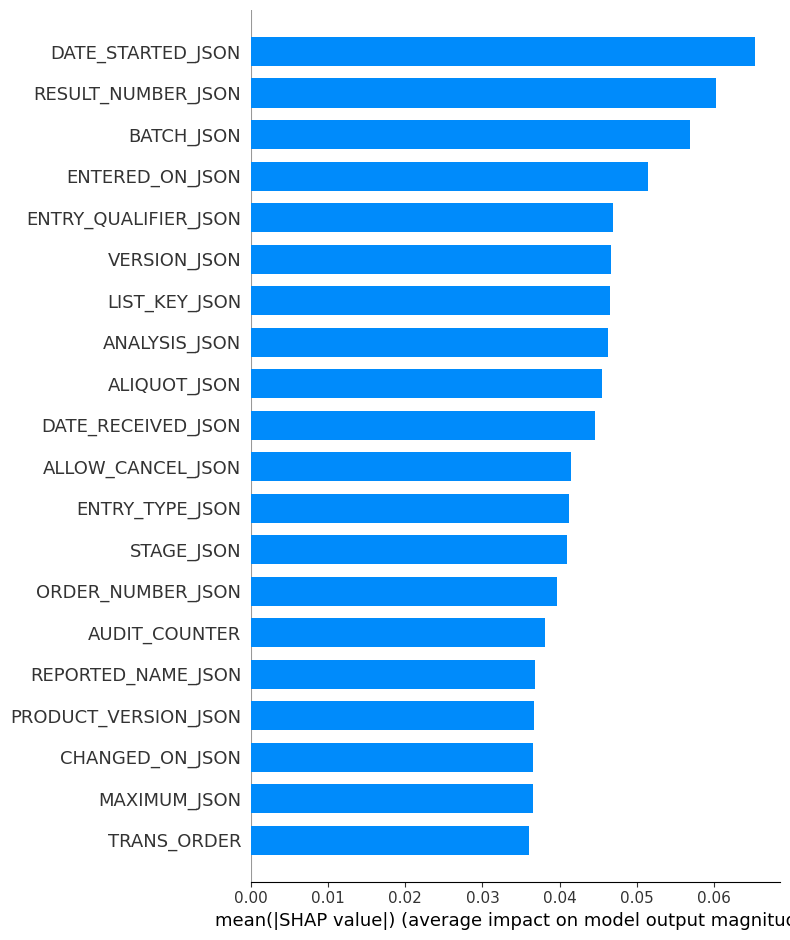

Error - Feature store file not found. Check directory.


PermutationExplainer explainer:  52%|█████▏    | 15503/29643 [2:10:23<1:59:05,  1.98it/s]


KeyboardInterrupt: 

In [57]:
# Start an MLflow run
mlflow.set_experiment("audit_type_based_testing") #Default 
algoType = "sklearn_if_single"


with mlflow.start_run(run_name=algoType, nested=True) as greatgrandparent_run:
    for FilterType in FilterTypeList: 
        with mlflow.start_run(run_name=f"Audit_Type_{FilterType}", nested=True) as grandparent_run:
            for customer in customerList:
                with mlflow.start_run(run_name=f"Run_{customer}", nested=True) as parent_run:
                    filepath = Path(f'C:/MLAR_DATA/T0001/FS_audit_type_table_name/{FilterType}/FS_audit_type_table_name_{FilterType}_{customer}.parquet')
                    if filepath.is_file()==True:
                        parquet = pd.read_parquet(filepath)
                        df = parquet.drop(['T0083','T0083_SEVERITY'],axis=1) #reduce some of customer specific ID-related features already removed 'LABEL_ID','LABEL_MASK','TEXT_ID_JSON'
                        df = df.astype(str).replace('nan',np.nan)
                        df.dropna(how='all', axis=1, inplace=True)
                        features = df.columns.tolist()
                        categoricalColumns = df.select_dtypes(include=['object']).columns.tolist()
                        encoder = CountFrequencyEncoder(encoding_method='frequency', variables=categoricalColumns, ignore_format=True)
                        dataFrame = encoder.fit_transform(df) 
                        train, test = train_test_split(dataFrame,test_size=0.30)

                        # Define model parameters
                        numTrees = 100
                        #sampleSize = 256
                        random = np.random.RandomState(1234)

                        # Initialize the model
                        if_model = IsolationForest(random_state=random)  
                        # Log model parameters and train
                        #mlflow.log_param("ntrees", numTrees)
                        #mlflow.log_param("sample_size", sampleSize)
                        if_model.fit(train)        
                        
                        # Predict anomalies and generate histogram
                        predictedTrain = if_model.predict(train) 
                        predictedTest = if_model.predict(test)            
                        
                        # Combine the scores with the original data
                        finalTrainDataframe = pd.concat([pd.DataFrame(data=predictedTrain,columns=['anomaly']),train],axis=1)
                        finalTestDataframe = pd.concat([pd.DataFrame(data=predictedTest,columns=['anomaly']),test],axis=1)
                        predictedDF = finalTrainDataframe[finalTrainDataframe['anomaly'] > 0]

                        #Export Dataset
                        mlflow.log_table(predictedDF,"predictedDF.json")

                        with mlflow.start_run(run_name=f"Explain_model", nested=True) as child_run:
                            #Train explaination model
                            explainer = shap.Explainer(if_model.predict, train)
                            shap_values = explainer.shap_values(test)
                            #mlflow.shap.log_explanation(shap_values, dataFrame)

                            #ra_plot = DRF_model.residual_analysis_plot(finalH2oFrame).figure()
                            #mlflow.log_figure(ra_plot, "residual_analysis_plot.png")
                            #vi_plot = DRF_model.varimp_plot().figure()
                            #mlflow.log_figure(vi_plot, "variable_importance_plot.png")
                            ss_plot = plt.figure(figsize=(9, 3))
                            shap.summary_plot(shap_values,test,plot_type="bar")
                            mlflow.log_figure(ss_plot, f"{customer}_{FilterType}_shap_summary_plot.png") 
                            #lc_plot = DRF_model.learning_curve_plot().figure()
                            #mlflow.log_figure(lc_plot, "learning_curve_plot.png")      

                            #predictContribution = DRF_model.predict_contributions(predictedH2oFrame)            

                    else:
                        print("Error - Feature store file not found. Check directory.")        
              

In [34]:
shap.plots.initjs()
shap.plots.force(explainer,shap_values)

c:\DSE\Python\Lib\site-packages\shap\plots\_force.py:208: UserWarning: shap.plots.force is slow for many thousands of rows, try subsampling your data.
  warnings.warn("shap.plots.force is slow for many thousands of rows, try subsampling your data.")


TypeError: unsupported operand type(s) for +: 'float' and 'PermutationExplainer'

In [ ]:
import statsmodels.api as sm 
fig = plt.figure(figsize=(14, 8)) 
fig = sm.graphics.plot_regress_exog(,f'{FilterType}',fig=fig) 

In [25]:
shapDf = pd.DataFrame(shap_values)

In [26]:
mlflow.shap.log_explanation(shapDf, dataFrame)

Provided model function fails when applied to the provided data set.


TypeError: 'DataFrame' object is not callable

In [ ]:
mlflow.log_figure(ss_plot, "shap_summary_plot.png") 

In [ ]:
mlflow.end_run()